In [14]:
from dataclasses import InitVar

import pylab as plt
import numpy as np

def σ_H2_diss_X_JRS(E, ΔE=18.15):
    """Dissociative ionization H2 -> H2+(X 2Σg+; ε) -> H+ + H(1s) in m^2, E in eV (Eq.␣
    ↪107a)."""
    E = np.asarray(E, dtype=float)
    x = np.clip(E/ΔE, 1, None)
    σ = 0.02905/x**1.25 * (1 - 1/x**2.78)**1.886 * 1e-16
    return np.where(E >= ΔE, σ*1e-4, 0.0) # cm^2 -> m^2
def σ_H2_diss_B_JRS(E, ΔE=30.6):
    """Dissociative ionization H2 -> H2+(B 2Σu+) -> H+ + H(1s) in m^2, E in eV (Eq.␣
    ↪107b)."""
    E = np.asarray(E, dtype=float)
    x = np.clip(E/ΔE, 1, None)
    σ = 0.5927/x**1.20 * (1 - 1/x**1.22)**3.375 * 1e-16
    return np.where(E >= ΔE, σ*1e-4, 0.0) # cm^2 -> m^2
def σ_H2_diss_JRS(E, η=1.0):
    """Total (effective) dissociative ionization H2 -> H+ in m^2; η = extraction␣
    ↪efficiency for fast protons."""
    return σ_H2_diss_X_JRS(E) + η*σ_H2_diss_B_JRS(E)


def σ_H2_ndiss_JRS(E, ΔE=15.42):
    """Non-dissociative ionization H2 -> H2+(X 2Σg+) in m^2, E in eV (zero below␣
    ↪threshold)."""
    E = np.asarray(E, dtype=float)
    x = np.clip(E/ΔE, 1, None)
    σ = 1.828/x * (1 - 1/x**0.92)**2.19 * np.log(2.05*ΔE*x) * 1e-16
    return np.where(E >= ΔE, σ*1e-4, 0.0) # cm^2 -> m^2

(10.0, 10000.0)

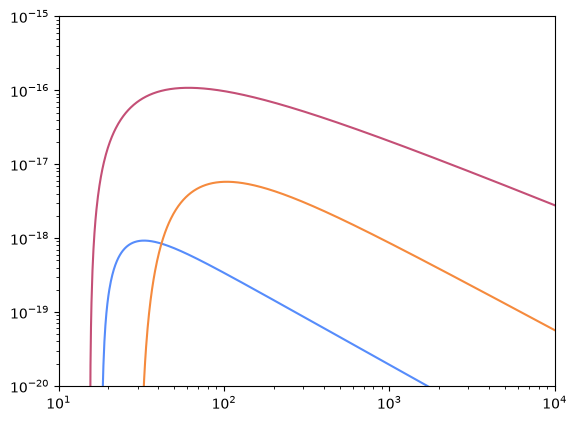

In [24]:
Es=np.logspace(1,4,1000)
plt.plot(Es,σ_H2_diss_X_JRS(Es)*1e4)
plt.plot(Es,σ_H2_diss_B_JRS(Es)*1e4)
plt.plot(Es,σ_H2_ndiss_JRS(Es)*1e4)

plt.loglog()
plt.ylim(1e-20,1e-15)
plt.xlim(1e1,1e4)

(17.0, 25.0)

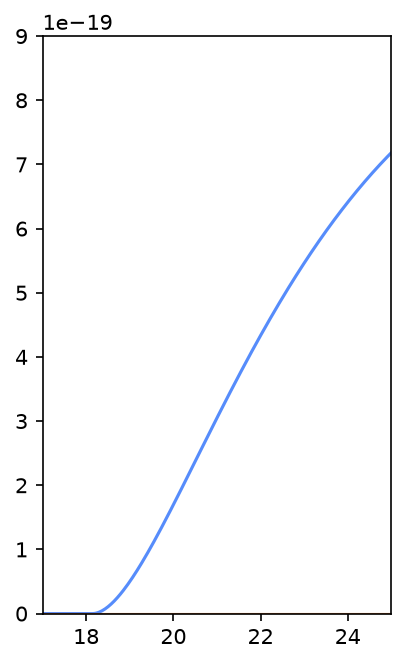

In [25]:
plt.figure(figsize=(3,5),dpi=150)

Es=np.linspace(15,50,1000)
plt.plot(Es,σ_H2_diss_X_JRS(Es)*1e4)
plt.plot(Es,σ_H2_diss_B_JRS(Es)*1e4)
plt.plot(Es,σ_H2_ndiss_JRS(Es)*1e4)
#plt.loglog()
#plt.loglog()
plt.ylim(0,9e-19)
plt.xlim(17,25)

In [1]:
v

NameError: name 'v' is not defined

In [2]:
1/48

0.020833333333333332

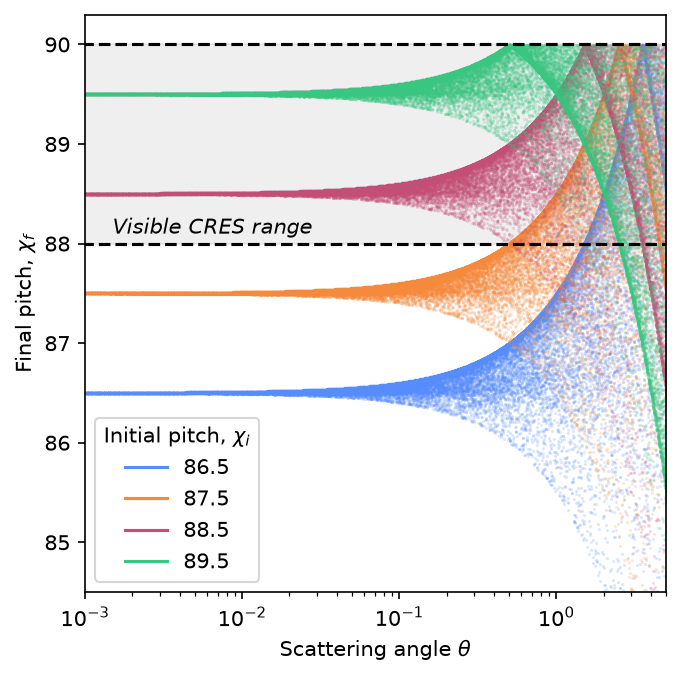

In [220]:

import pylab as plt
import numpy as np

samples=50000
InitialPhi=0

colors=['C0','C1','C2','C3']

ScatAngle=1*np.pi/180
InitialChi=89*np.pi/180
MaxAngle=5*np.pi/180
c=0
plt.figure(figsize=(5,5),dpi=150)
plt.fill_between([1e-3,5],[88,88],[90,90],color='dimgrey',alpha=0.1)
for InitialChi in np.array((86.5,87.5,88.5,89.5))*np.pi/180:
    ScatAngles=[]
    NewChis=[]
    for i in range(0,samples):
        ScatAngle=10**(1-(np.random.uniform())*4)*np.pi/180
        ScatAngles.append(ScatAngle)

        Vi=np.array([np.sin(InitialChi)*np.cos(InitialPhi),np.sin(InitialChi)*np.sin(InitialPhi),np.cos(InitialChi)])
        RandomTheta=np.random.uniform()
        RandomPhi=np.random.uniform()
        RandomVector=np.array([np.sin(RandomTheta)*np.cos(RandomPhi),np.sin(RandomTheta)*np.sin(RandomPhi),np.cos(RandomTheta)])

        ScatteringPlane=np.cross(RandomVector,InitialVector)
        k=ScatteringPlane/np.sqrt(sum(ScatteringPlane**2))

        Vf=Vi*np.cos(ScatAngle)+np.cross(k,Vi)*np.sin(ScatAngle)+k*np.dot(k,Vi)*(1-np.cos(ScatAngle))
        NewChi=np.arctan2(np.sqrt(Vf[0]**2+Vf[1]**2),Vf[2])
        if(NewChi>np.pi/2):
            NewChi=np.pi-NewChi
        NewChis.append(NewChi)

    NewChis=np.array(NewChis)
    ScatAngles=np.array(ScatAngles)

    plt.plot(ScatAngles*180/np.pi,NewChis*180/np.pi,'.',markersize=1,alpha=0.2,color=colors[c])
    plt.plot([-1],[-1],color=colors[c],label=str(round(InitialChi*180/np.pi,1)))

    c=c+1
plt.xlabel(r"Scattering angle $\theta$")
plt.ylabel(r"Final pitch, $\chi_f$")
plt.xlim(1e-3,5)
plt.ylim(84.5,90.3)
plt.plot([0,5],[90,90],'--',color='black')
plt.plot([0,5],[88,88],'--',color='black')
plt.text(1.5e-3,88.1,'Visible CRES range',color='black',style='italic')
plt.legend(loc='lower left',title=r'Initial pitch, $\chi_i$')

plt.semilogx()
plt.savefig("NewPitchAngle.png",dpi=200)

In [137]:
import kinematics
import constants

/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_51403/2546617998.py:22: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0,5)


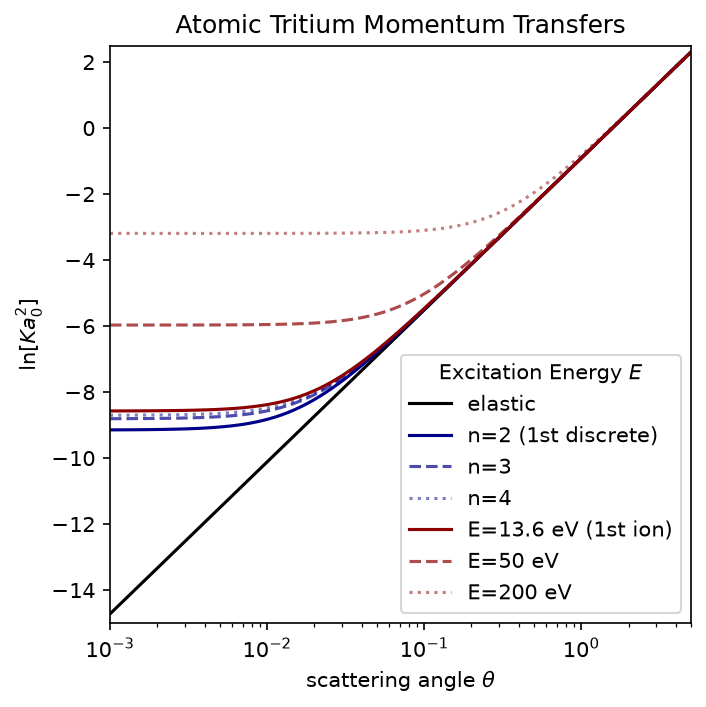

In [219]:
plt.figure(figsize=(5,5),dpi=150)
thetas=np.logspace(-3,1,100)
T=18000
ci=0
M=constants.mT
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,0,M)),label='elastic',color='black')
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,kinematics.En(2),M)),label='n=2 (1st discrete)',color='DarkBlue')
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,kinematics.En(3),M)),'--',label='n=3 ',color='DarkBlue',alpha=0.7)
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,kinematics.En(4),M)),':',label='n=4 ',color='DarkBlue',alpha=0.5)

plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,13.6,M)),label=r'E=13.6 eV (1st ion)',color='DarkRed')
plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,50,M)),'--',label='E=50 eV',color='DarkRed',alpha=0.7)

plt.plot(thetas, np.log(kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,200,M)),':',label='E=200 eV',color='DarkRed',alpha=0.5)
plt.legend(loc='lower right',title='Excitation Energy $E$')
plt.title("Atomic Tritium Momentum Transfers")

plt.semilogx()
plt.xlabel(r"scattering angle $\theta$")
plt.ylabel(r"ln[$Ka_0^2$]")
ci=ci+1
plt.xlim(0,5)
plt.ylim(-15,2.5)
plt.xlim(1e-3,5)
plt.savefig("KinLimits.png",dpi=200)


In [168]:
kinematics.En(100)

13.59864

In [161]:
kinematics.GetKa2FromCosTheta(np.cos(thetas*np.pi/180),T,0,2.*M)


array([4.03135678e-03, 2.52978507e-02, 6.48276378e-02, 1.22620445e-01,
       1.98675874e-01, 2.92993399e-01, 4.05572371e-01, 5.36412012e-01,
       6.85511419e-01, 8.52869563e-01, 1.03848529e+00, 1.24235732e+00,
       1.46448424e+00, 1.70486453e+00, 1.96349652e+00, 2.24037843e+00,
       2.53550835e+00, 2.84888424e+00, 3.18050394e+00, 3.53036516e+00,
       3.89846549e+00, 4.28480239e+00, 4.68937319e+00, 5.11217510e+00,
       5.55320521e+00, 6.01246046e+00, 6.48993769e+00, 6.98563361e+00,
       7.49954480e+00, 8.03166771e+00, 8.58199866e+00, 9.15053387e+00,
       9.73726940e+00, 1.03422012e+01, 1.09653251e+01, 1.16066369e+01,
       1.22661320e+01, 1.29438059e+01, 1.36396540e+01, 1.43536714e+01,
       1.50858533e+01, 1.58361945e+01, 1.66046900e+01, 1.73913343e+01,
       1.81961221e+01, 1.90190478e+01, 1.98601057e+01, 2.07192901e+01,
       2.15965950e+01, 2.24920143e+01, 2.34055419e+01, 2.43371714e+01,
       2.52868965e+01, 2.62547106e+01, 2.72406070e+01, 2.82445789e+01,
      